# Notebook 91: selected metrics from Notebook 90

Saved offline heuristic (A), online heuristic (B), and full-training comparison from N90, through 57,600 offered continuation images. Dotted lines mark the warm parent. Full training uses more updates; this is a one-seed comparison. Reconstruction is fixed-bank loss; trained-image reconstruction is the loss on accepted training images.

## Methods

All three methods continue image-reconstruction training from the same warm parent on the same ordered image stream (seed 5003). A and B also share the augmentation and acceptance-RNG seeds. Each accepted image produces one model update.

### A: Offline heuristic

A reuses N84's saved run. "Offline" means that its admission predictor was fitted beforehand and remains frozen; the image model continues learning. The predictor estimates how an update would change J: fixed-bank reconstruction relative to the warm parent, plus penalties for reduced RankMe and variance (weight 0.25 each). A lower J is preferred. Predictions below the calibrated negative threshold receive a 50% update probability; other negative predictions receive 25%, and nonnegative predictions receive 10%. Unavailable or heavily clipped predictions fall back to 25%. This preserves some learning opportunities even when predictions are unfavorable.

Fixed-bank health is checked every 128 arrivals. The normal learning rate is one quarter of nominal; persistent loss of rank/variance, or jointly elevated covariance and reconstruction loss, switches it to one sixteenth. If fewer than eight updates occur in the preceding 256 arrivals, a short burst supplies 16 consecutive updates at the smaller rate. Development checks can refresh the backup and health reference, but task-based rollback is disabled. Numerical failures still trigger restoration and bounded recovery.

### B: Online heuristic

B has two distinct learners. The **image model** is the encoder and reconstruction decoder: an accepted image produces one self-supervised AdamW update that minimizes masked-image reconstruction error. The **online task predictor** is a separate, small linear regression model. It learns which proposed image updates are likely to help the development classification task, and uses that prediction to adjust the chance of accepting an image. Its regression objective does not replace the image model's reconstruction loss or backpropagate into the encoder.

#### What is it trained on?

One training example is a pair of **pre-update features** and the **task-error change observed after an accepted image update**. It is not a regression trained directly on raw images or their reconstruction targets. The runner measures the current encoder using linear classifiers fitted on labeled development support images and evaluated on separate development query images. The same support/query identities are used across measurements, and the classifiers are refitted after accepted image updates.

The task score S is a smooth classification-error measure averaged over the balanced development query panel and reader support draws. For each query image, take the linear classifier's probability of its true class, p_true, and compute `sigmoid((0.5 - p_true) / 0.05)`. Confident correct predictions contribute near zero; incorrect predictions contribute near one. S changes smoothly near the decision boundary, even when ordinary accuracy has not changed. It is neither cross-entropy nor reconstruction loss.

The regression label is `y = S_after - S_before`, measured across that one accepted update. A negative label means immediate development-task improvement; a positive label means deterioration. The first arrival is excluded from predictor training. Rejected images and numerically failed updates provide no observed training label: their hypothetical effects are not treated as zero. Thus the predictor learns from the updates B actually accepts, rather than from outcomes for every offered image.

This makes the controller **task-informed**: development class labels supply both its outcome measurements and a task-gradient feature. The image update itself remains self-supervised. The separate final evaluation labels are used only for reporting, and never train this predictor or choose admission decisions.

#### What does it see before making a prediction?

The predictor receives 19 numeric inputs, all available before executing the candidate update:

| Input group | Count | Contents |
| --- | ---: | --- |
| Current representation health | 4 | RankMe, variance, covariance, fixed-bank reconstruction |
| Recent health changes | 4 | Preceding-arrival changes in those same four measurements |
| Candidate update information | 5 | Candidate training-view reconstruction loss, gradient norm, gradient/momentum cosine, proposed AdamW displacement norm, and development cross-entropy-gradient/displacement cosine |
| Image novelty | 2 | Distance from the warm feature centroid and nearest-recent-offered-image cosine distance |
| Controller and task context | 4 | Frozen J forecast, candidate learning-rate factor, caution-mode indicator, and preceding development soft error |

The gradient/displacement features describe a proposed update using the current model and optimizer state. Computing these features does not apply the image update. The task-gradient cosine measures the relationship between the proposed displacement and the development classification-loss gradient; it is a feature, not the predictor's training label.

#### What objective does the predictor optimize?

It uses **exponentially discounted ridge regression**: choose linear coefficients that minimize squared error between predicted and observed task-error changes, with a penalty on coefficient size. In compact form, the objective is:

```text
sum over past labeled updates i:
    gamma^(t-i) * (beta dot phi(x_i) - y_i / target_scale)^2
plus 10 * sum(feature_coefficients^2) + 0.1 * intercept^2
```

Here phi contains the standardized/clipped inputs plus an intercept, and `gamma = 2^(-1/256)`. An observation therefore has half its original weight after 256 later labeled accepted updates. This discount lets the predictor adapt as the image model changes; it is not retrained from scratch after each image.

The first 128 labeled accepted updates initialize input means, input standard deviations, target scale, and the initial regression. Input scaling then stays fixed, standardized coordinates are clipped to [-5, 5], and coefficients continue updating from subsequent accepted outcomes. The model has 19 feature coefficients and one intercept. Ridge regularization limits unstable coefficients when features are correlated and individual task changes are small.

#### What does it predict, and how does that affect training?

Before deciding whether to train on an arriving image, it predicts a **signed scalar change in development soft error if that image receives the proposed update**. Predictions are converted back to the original soft-error units. This is an estimate of immediate update benefit, not a probability of improvement, a prediction of final accuracy, or a prediction of J. The trace also stores zero-change, recent-mean, and initialization-frozen regression predictions as diagnostic baselines; only the continually updated regression controls B.

Once initialized, B takes A's ordinary admission probability p and applies:

- Predicted change below zero: `p_new = clip(1.2 * p, 0.05, 0.95)`.
- Predicted change above zero: `p_new = clip(0.8 * p, 0.05, 0.95)`.
- Zero/nonfinite prediction, or predictor not initialized: leave p unchanged.

For example, A's 25% probability becomes 30% for predicted benefit or 20% for predicted harm. The multiplier uses the prediction's sign, not its magnitude. The seeded acceptance draw then determines whether the update happens. This adjustment applies only to ordinary decisions in normal/caution mode; forced bursts and numerical recovery keep A's rules. N91's predictor changes admission probability, while the existing health controller still determines learning rate.

The order is **compute features and predict, make the admission decision, execute an accepted image update, measure its actual development effect, then update the regression**. That outcome can influence future decisions, but cannot influence the prediction already made for the same image. B retains the fixed bank, J weights, health/rate rules, bursts, numerical recovery, and disabled task-based rollback.

#### What is the limitation of this objective?

The target covers one immediate update and one repeatedly observed development panel. Predicting it well does not establish that the chosen update improves later evaluation accuracy. Rejected-image outcomes remain unknown, and the model sees the selection bias created by its own policy. N91 therefore reports a bounded, task-informed admission experiment. The separate N92 experiment extends feedback to complete windows and explores rates; those mechanisms are not part of N91's B results.

### Full training

The saved full-exposure reference updates on every offered image and therefore uses a larger training budget. The plotted comparison is one paired seed and is not matched for update count.


## Balanced linear accuracy (%)
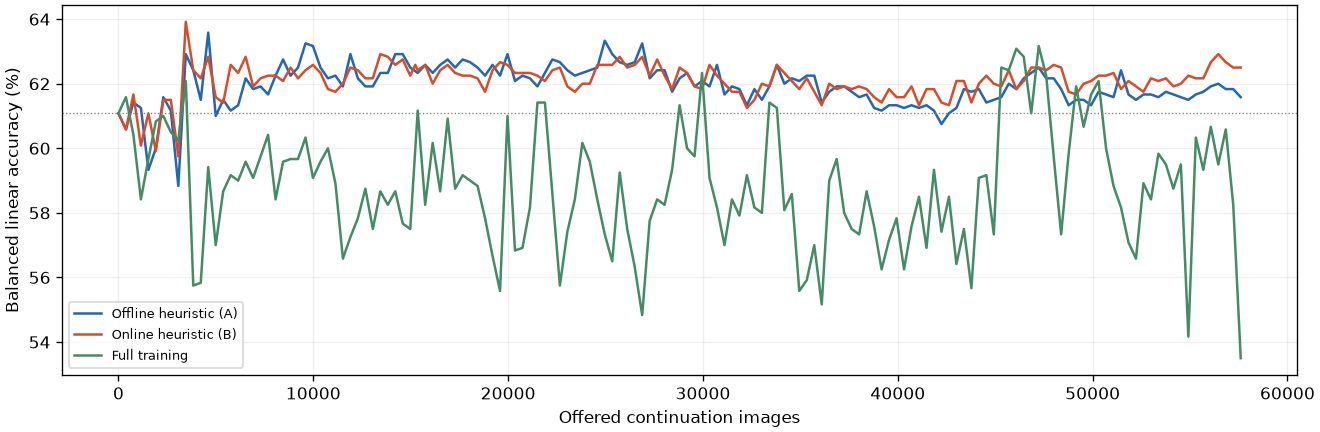

## RankMe
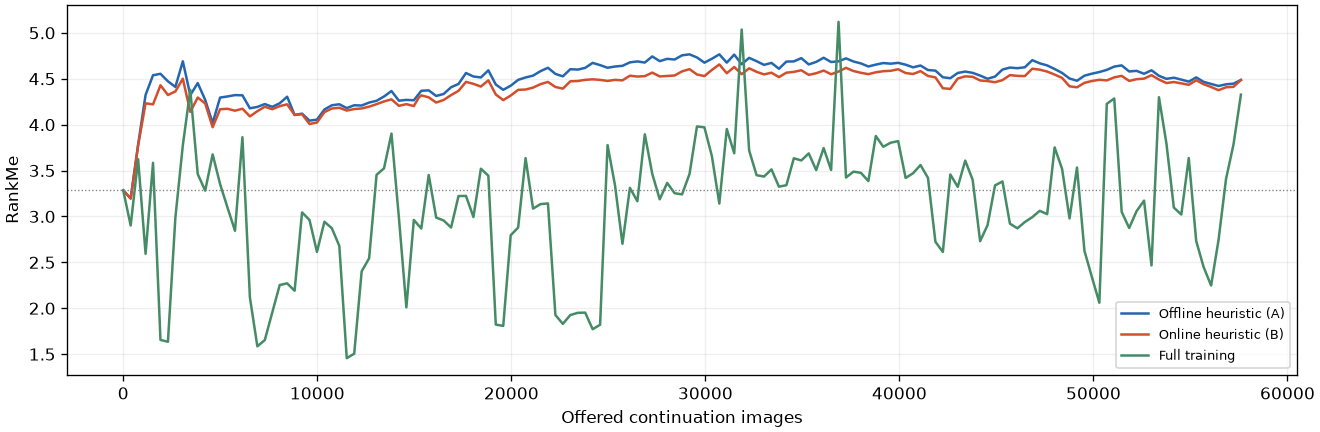

## Variance
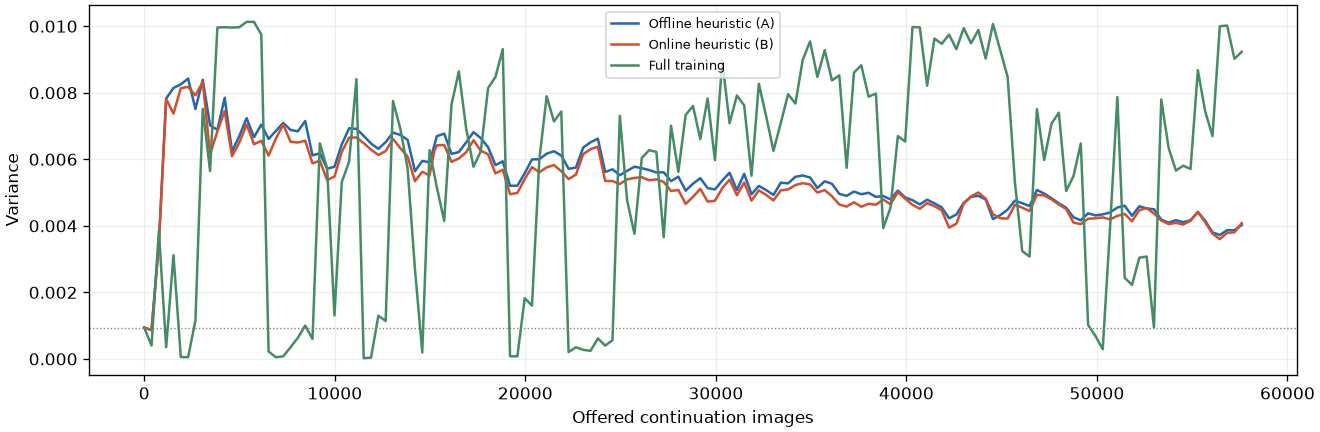

## Covariance
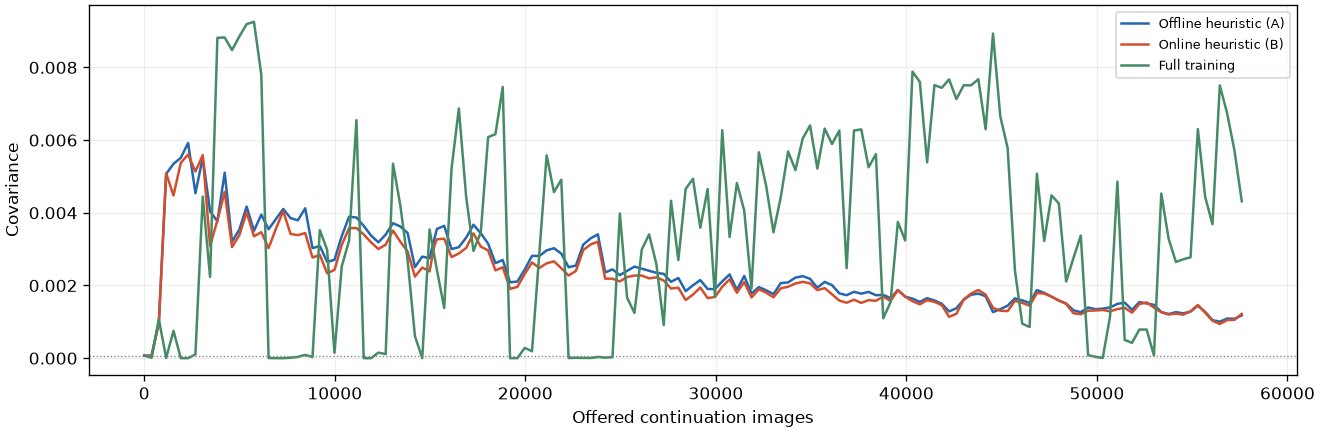

## Reconstruction (fixed bank)
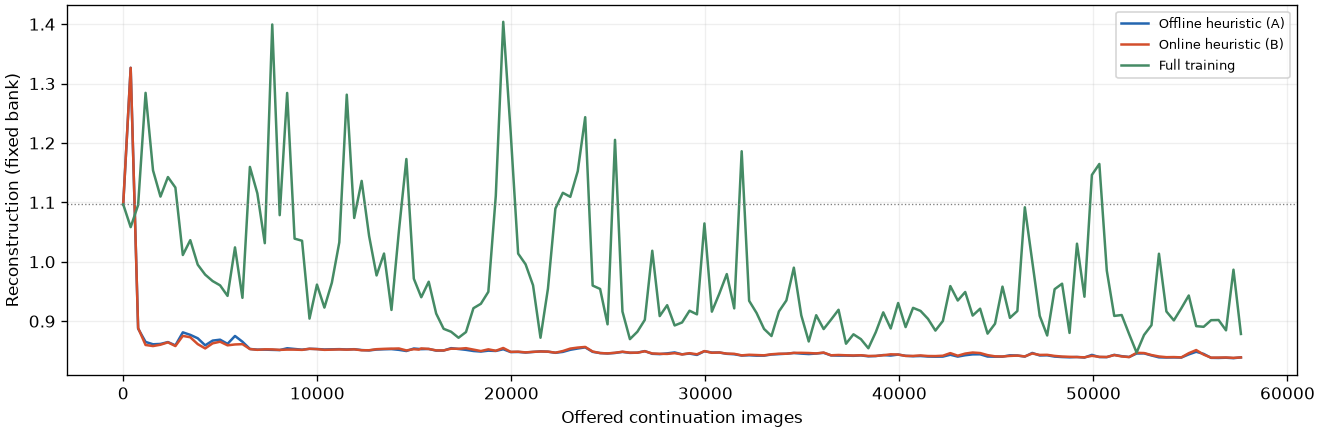

## Trained image reconstruction
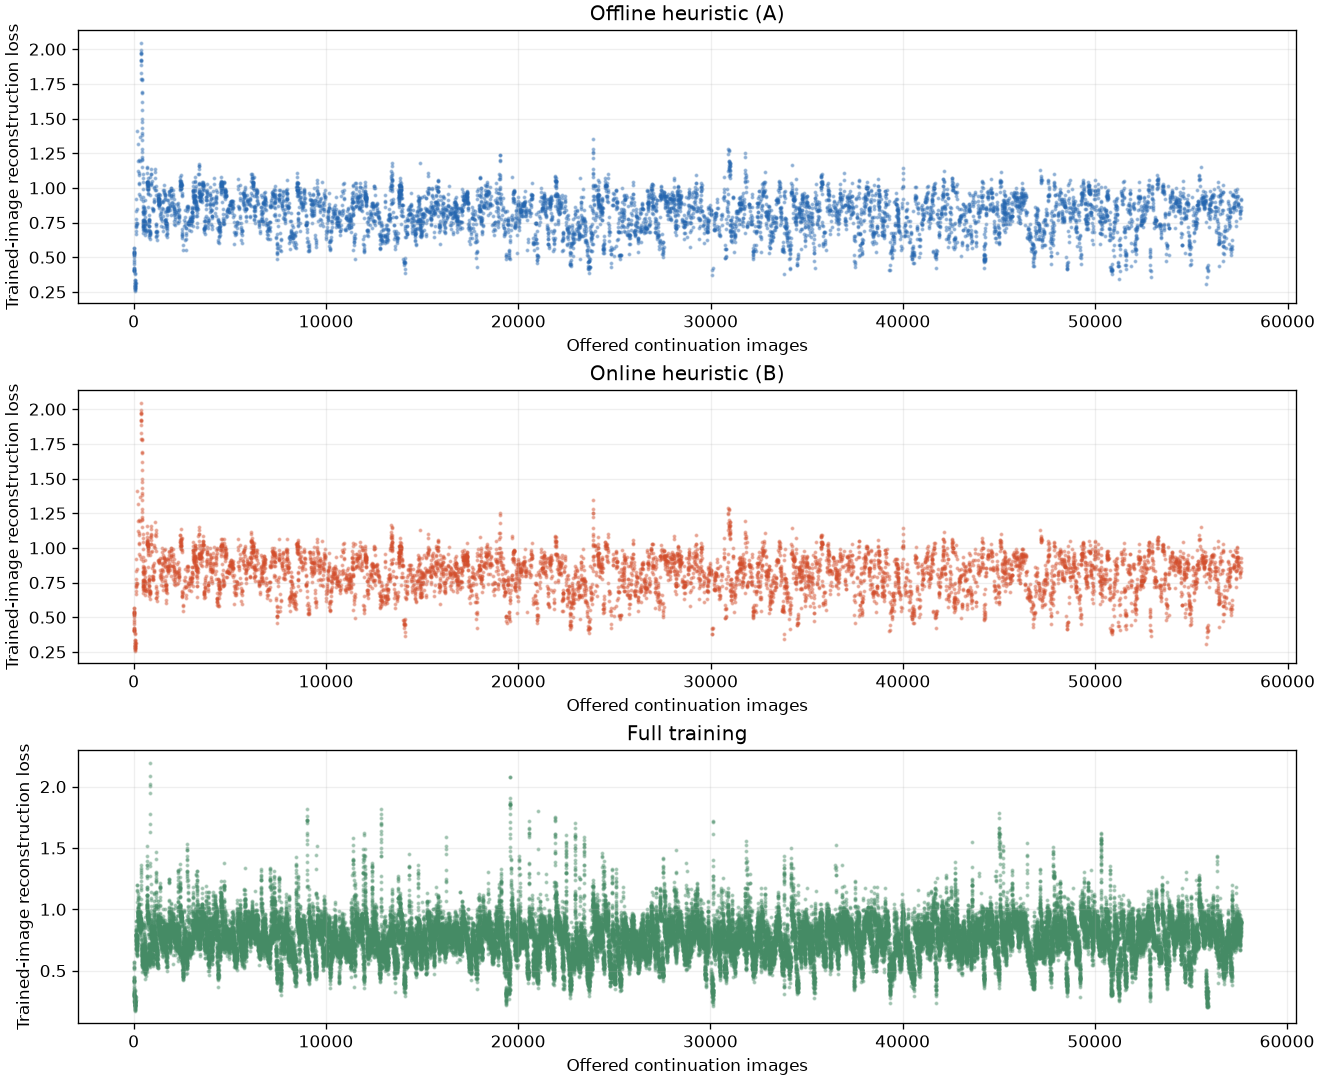